# Introduction to CHRPP and CHRPYPY


This jupyter notebook serves as support for the course introduction to CHRPP. It contains the examples presented in the slides along with complementary explanations on how to use CHRPYPY.

## CHRPYPY

CHRPYPY is a collection of wrappers and helper functions that uses CHRPP as backend to write and execute CHR programs. It still requires compilation before executing any program (it takes around 10-ish seconds). Once compiled, if no changes to rules are done, the program can be called with any constraint without re-compiling.

CHRPYPY is not yet available on PyPI. To install CHRPYPY, run the following cell (it requires compiling CHRPPC, which can take some time, it is required once per session, upon re-running the following cell, an error like "fatal: destination path 'install_chrpypy' already exists and is not an empty directory" is awaited).

Google Colab currently ships Python 3.13. CHRPYPY supports it, and the install command below uses `--ignore-requires-python` so it also works when the checked-out package metadata still advertises a newer Python version.


In [ ]:
# Colab currently uses Python 3.13. The flag keeps the install working even if
# the cloned package metadata still declares a newer minimum Python version.
!git clone https://github.com/owrel/chrpypy.git install_chrpypy && cd install_chrpypy && pip install --no-build-isolation --no-cache-dir --ignore-requires-python .


**Note**

 This command is exclusive to notebooks, for "classical" installation, please refer to the repo installation guide.

 If an error occured during installation, please duplicate this notebook and add -v to previous command. If the error persist, send the trace to aurelien.simon@univ-angers.fr

 If you want to update chrpypy, use the following command :
 `!rm -rf install_chrpypy && git clone https://github.com/owrel/chrpypy.git install_chrpypy && cd install_chrpypy && CHRPP_IGNORE_CACHE=1 pip install --no-build-isolation --no-cache-dir --ignore-requires-python .`


In [ ]:
# Checking if installation succeed
from chrpypy import Program

# Let's start by an exemple

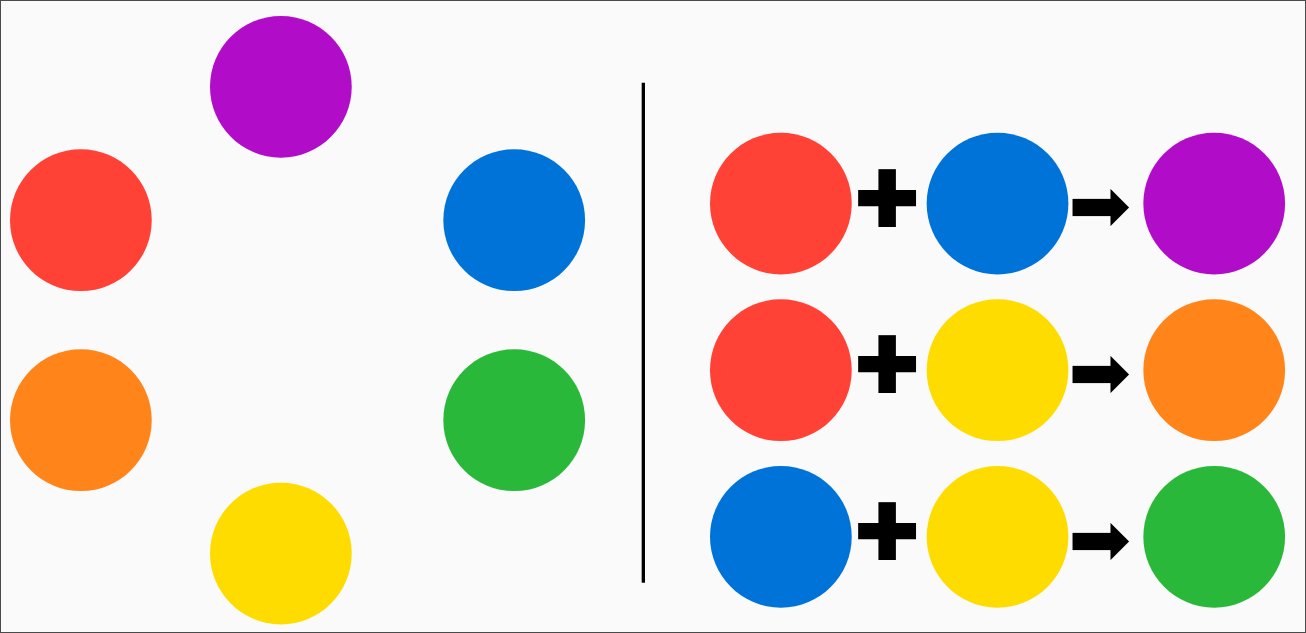

## Program

The program class is the main entry to create CHR programs, this class contains methods to create rules, constraint store and handle compilation flow.

Useful helpers:
- `program.chr()` returns the CHR rules as text (`str(program)` does the same).
- `program.to_chrpp()` returns the generated CHR++ code.
- `program.store()` returns the current constraints.
- `program.clear_rules()` and `program.clear_constraints()` remove rules/constraints, while `program.reset_store()` empties the store.


In [ ]:
program = Program("ColorPalette", folder="./cp", compile_on="compile")
# Compile trigger allows us to control when the compilation occurs

## Constraint Store

Constraint stores serve two functionnality :
- Creating constraints
- Posting constraints

In [ ]:
red = program.constraint("red", []) # We define here the name of the constraint and the list of types of arguments
red

red() : ~[]

~ means here that the program is not compiled yet, so constraint store is considered empty

In [ ]:
blue = program.constraint("blue", [])
yellow = program.constraint("yellow", [])
purple = program.constraint("purple", [])
orange = program.constraint("orange", [])
green = program.constraint("green", [])
# All colors

## Rules
Rules can be added directly from CHR source text with `program.parse_rule(...)`. This is the most compact way to write them, and it uses the same syntax as CHRPP. The programmatic API (`simplification()`, `propagation()`, and `simpagation()`) remains available when you need to build rules dynamically.

Let's start by simplification.


In [ ]:
program.parse_rule("purple @ red(), blue() <=> purple()")


In [ ]:
program.parse_rule("orange @ red(), yellow() <=> orange()")


In [ ]:
program.parse_rule("green @ blue(), yellow() <=> green()")


In [ ]:
program.compile() # compilation takes some time (especially on google collab)

Once the program is compiled, we can then post constraints to trigger rules.
On using
```python
<constraint>.post(...)
```

In [ ]:
blue.post()

[blue()]

In [ ]:
red.post()

[purple()]

In [ ]:
program.reset_store()

[]

### Let's add an absorbing color

Simpagation rules keep part of the head and remove the rest. In CHR text, `\` separates the preserved head from the removed head:

```chr
name @ positive_head \ negative_head <=> guard | body
```

They are added with `program.parse_rule(...)`.

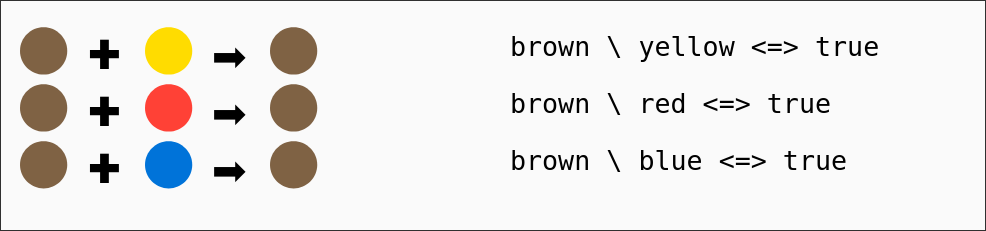



In [ ]:
brown = program.constraint("brown", [])

In [ ]:
program.parse_rule("brown_eat_yellow @ brown() \\ yellow() <=> true")


In [ ]:
program.parse_rule("brown_eat_red @ brown() \\ red() <=> true")


In [ ]:
program.parse_rule("brown_eat_blue @ brown() \\ blue() <=> true")


## Transmutation of lead into gold

Let's implement another example and transmute some lead

```
philosopher_stone \ lead <=> gold
```

In [ ]:
from chrpypy import Program
program = Program("transmutation", folder = "./transmu", compile_on = "compile")

philosopher_stone = program.constraint("philosopher_stone", [])
lead = program.constraint("lead", [])
gold = program.constraint("gold", [])

program.parse_rule("philosopher_stone() \\ lead() <=> gold()")

program.compile()

philosopher_stone.post()
lead.post()

print(program.chr())
print(program.store())


## Summary

*   Head <=> Body : the body replaces the head -> `program.parse_rule("name @ Head <=> Body")`
*   Head_k \ Head_r <=> Body : the body replaces the removed head -> `program.parse_rule("name @ Head_k \\ Head_r <=> Body")`
*   Head ==> Body : the body is added where the head is present -> `program.parse_rule("name @ Head ==> Body")`

The programmatic builders `program.simplification(...)`, `program.simpagation(...)` and `program.propagation(...)` remain available for rules constructed dynamically in Python.


## Adding information to constraints

Constraints can take arguments, to do so in CHRPYPY, we need to define constraint stores with the types of the different arguments.

Types can also be inferred lazily: calling `program.constraint("name")` without types creates a store whose types are inferred from the values used when the constraint is posted.

Inside of parsed CHR rules, variables are simply written by name (for example `I`, `J`) in the rule text. When building rules programmatically, the same names can be created with `program.symbols(...)`.


In [ ]:
from chrpypy import Program
program = Program("bank", "bk", compile_on="compile")

piggy_bank = program.constraint("piggy_bank", [int])


In [ ]:
program.parse_rule("sum @ piggy_bank(I), piggy_bank(J) <=> piggy_bank(I + J)")


In [ ]:
program.compile()

Implement the following post order :


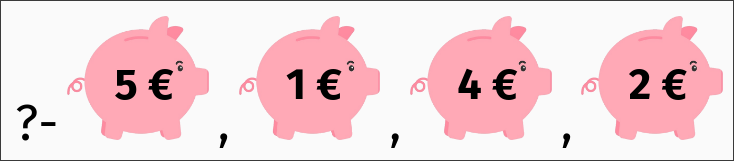




In [ ]:
piggy_bank.post(5)

[piggy_bank(5)]

In [ ]:
piggy_bank.post(1)

[piggy_bank(6)]

In [ ]:
piggy_bank.post(4)

[piggy_bank(10)]

In [ ]:
piggy_bank.post(2)

[piggy_bank(12)]

In [ ]:
print(program.store())


## Conditioning the triggering of rules

In CHRPYPY, we can add guard using the named parameter "guard" in any rules.
```python

program.<rule>(head=..., guard=..., body=...)

```

Guard are built implicitly using `chrpypy` object in the expression. For instance :

In [ ]:
# GOOD
from chrpypy import Guard
I = program.symbol("I")
print(I > 1)
print(isinstance(I > 1, Guard))


In [ ]:
# WRONG
print(2 > 1) # It is a python expression ; nothing related to chrpypy
print(isinstance(2 > 1, Guard))

True
False


In [ ]:
# GOOD
from chrpypy import Constant
print(2 > Constant(1)) # will be re-ordered
print(isinstance(2 > Constant(1), Guard))

1 < 2
True


Now, we implement the two following rule

```
piece(I), piggy_bank(J) <=> I >= 1 | piggy_bank(I+J)
piece(I), piggy_bank_cents(J) <=> I < 1 | piggy_bank_cents(I+J)
```


In [ ]:
from chrpypy import Program
program = Program("bank_extended", "bke", compile_on="compile")

piece = program.constraint("piece", [float])
piggy_bank = program.constraint("piggy_bank", [float])
piggy_bank_cents = program.constraint("piggy_bank_cents", [float])

program.parse_rule("sum @ piece(I), piggy_bank(J) <=> I >= 1 | piggy_bank(I + J)")

program.parse_rule("cent @ piece(I), piggy_bank_cents(J) <=> I < 1 | piggy_bank_cents(I + J)")

print(program.chr())


In [ ]:
program.compile()
program.store()


In [ ]:
# Initialisation
piggy_bank.post(0.0)
piggy_bank_cents.post(0.0)

[piggy_bank(0.0), piggy_bank_cents(0.0)]

In [ ]:
piece.post(1.5)

[piggy_bank(1.5), piggy_bank_cents(0.0)]

In [ ]:
piece.post(0.5)

[piggy_bank(1.5), piggy_bank_cents(0.5)]

## Let's factor the color mixing program.

```prolog
color("red"), color("blue") <=> color("purple")
color("red"), color('yellow") <=> color("orange")
color("blue"), color("yellow") <=> color("green")
color("brown") \ color(_) <=> true

color(X) \ color(Y) <=> X == Y | true
```



In [ ]:
from chrpypy import Program
program = Program("ColorPaletteFactorized", "cp_factorized", compile_on="compile")

color = program.constraint("color", [str])

program.parse_rule('color("red"), color("blue") <=> color("purple")')
program.parse_rule('color("red"), color("yellow") <=> color("orange")')
program.parse_rule('color("blue"), color("yellow") <=> color("green")')

program.parse_rule('color("brown") \\ color(_) <=> true')

program.parse_rule('color(X) \\ color(Y) <=> X == Y | true')

program.compile()


In [ ]:
color.post("red")
color.post("blue")

[color("purple")]

In [ ]:
color.post("red")
color.post("yellow")

[color("purple"), color("orange")]

In [ ]:
color.post("orange") # remove duplicate

[color("purple"), color("orange")]

In [ ]:
color.post("magenta")

[color("purple"), color("orange"), color("magenta")]

In [ ]:
color.post("brown")

[color("brown")]

## Logical Variable

Rules use **rule variables** (symbols such as `X` and `Y`) that match constraint arguments. A **logical variable** is different: it is a typed Python object created with `program.logicalvar(...)` and posted as a constraint argument.

When a rule unifies a rule variable with that argument (`res(X), gcd(Y) <=> X %= Y`), the logical variable is bound to the matched value. The logical variable itself is therefore still managed from Python, not declared in the CHR rule text.


In [ ]:
from chrpypy import Program
program = Program("min_with_logicalvar", "minlv", compile_on="compile")

min = program.constraint("gcd", (int,))
res = program.constraint("res", (int,))

program.parse_rule("gcd(X) \\ gcd(Y) <=> X <= Y | true")

program.parse_rule("res(X), gcd(Y) <=> X %= Y")

program.compile()


In [ ]:
Res = program.logicalvar("Res", int)  # typed logical variable, created on the Python side
min.post(15)
min.post(3)
res.post(Res)


In [ ]:
Res.value()


## Reactivation of rules

In [ ]:
from chrpypy import Program

def print_hello():
  print("hello")

def print_world():
  print("world")

program = Program(name="reactivation", folder="reac", compile_on="compile")

c = program.constraint("c", [str])

# Register the Python callbacks referenced by name in the parsed rules.
program.function(print_hello)
program.function(print_world)

program.parse_rule('c("hello") <=> print_hello()')
program.parse_rule('c("world") <=> print_world()')

program.compile()


In [ ]:
print(program.chr())


The callbacks are registered with `program.function(...)` and referenced by name in the parsed rule bodies (`print_hello()` and `print_world()`). The registration is applied automatically when the program is compiled.


In [ ]:
X = program.logicalvar("X", str)

In [ ]:
c.post(X)

[c(X)]

In [ ]:
X.unify("hello")

hello


In [ ]:
Y = program.logicalvar("Y", str)


In [ ]:
c.post(Y)

[c(Y)]

In [ ]:
c.post("world")

world


[c(Y)]

In [ ]:
Y.unify("hello")

hello


## The inequality constraint

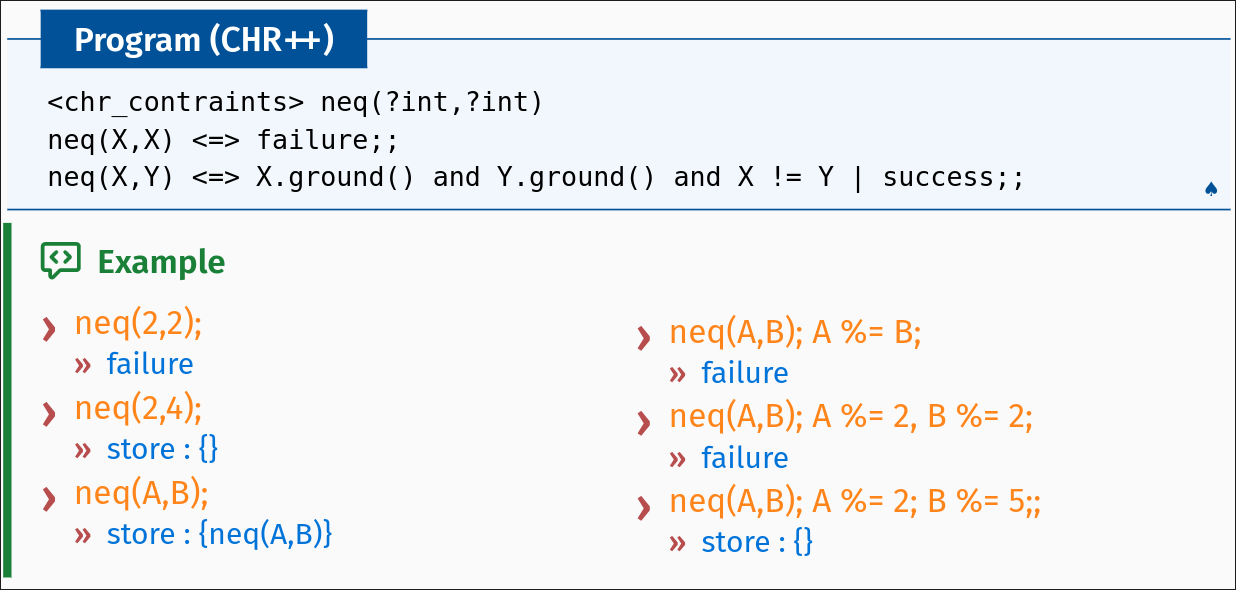

In [ ]:
from chrpypy import Program

program = Program(name="inequality", folder="inequality", compile_on="compile")

neq = program.constraint("neq", [int, int])

program.parse_rule("neq(X, X) <=> failure")

program.parse_rule(
    "neq(X, Y) <=> X.ground() and Y.ground() and X != Y | success"
)

program.compile()


In [ ]:
# neq(2,2);
neq.post(2, 2)
program.store()


In [ ]:
# neq(2,4);
try:
  neq.post(2, 4)
except Exception as e:
  print(e)

Program is in failure state ; cannot post


In [ ]:
program.failed()

True

In [ ]:
program.reset_program()
program.failed() # Reset the failure state

False

In [ ]:
neq.post(2,4)
program.store()


In [ ]:
# neq(A,B)
A = program.logicalvar("A", int)
B = program.logicalvar("B", int)
neq.post(A, B)

[neq(A, B)]

In [ ]:
print(A._get_value_raw())
print(B._get_value_raw())

?0xc5580b0
?0xc558b10


In [ ]:
# neq(A,B), A %= B
A.unify(B)
program.store()


In [ ]:
program.reset_program()

In [ ]:
print(A._get_value_raw())
print(B._get_value_raw())

?0xc5580b0
?0xc5580b0


In [ ]:
#neq(A,B), A %= 2, B %= 2
A = program.logicalvar("A", int)
B = program.logicalvar("B", int)
neq.post(A, B)

[neq(A, B)]

In [ ]:
A.unify(2)
program.store()


In [ ]:
B.unify(2)
program.store()


In [ ]:
program.reset_program()

In [ ]:
#neq(A,B), A %= 2, B %= 5
A = program.logicalvar("A", int)
B = program.logicalvar("B", int)
neq.post(A, B)
program.store()

In [ ]:
A.unify(2)
program.store()


In [ ]:
B.unify(5)
program.store()



## Exercice 1

One CHR constraint: min(int) with an integer argument.
What rule(s) to write so that only the min constraint remains whose
argument is the smallest value?

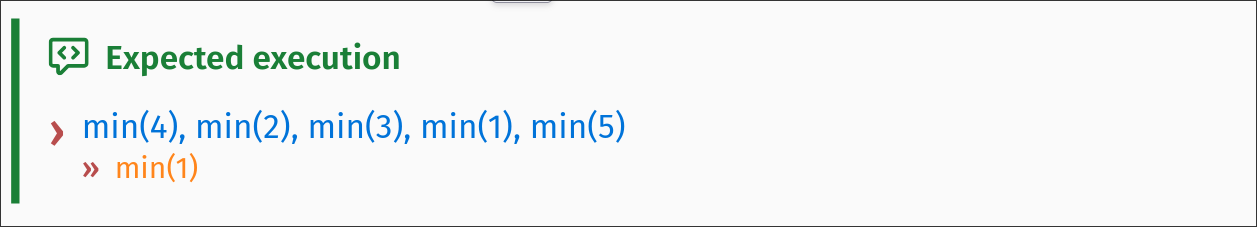

In [ ]:
# Implement min there ...